--- Loading and Exploring Dataset ---
Class 'apple': 2000 samples, shape=(784,)
Class 'car': 2000 samples, shape=(784,)
Class 'cat': 2000 samples, shape=(784,)
Class 'clock': 2000 samples, shape=(784,)
Class 'fish': 2000 samples, shape=(784,)
Class 'house': 2000 samples, shape=(784,)
Class 'star': 2000 samples, shape=(784,)
Class 'tree': 2000 samples, shape=(784,)


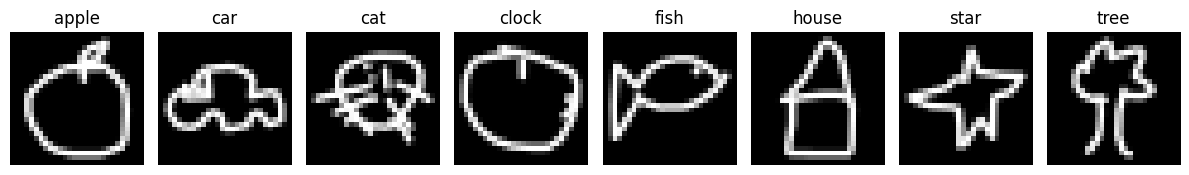

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Define the 8 target classes from quickdraw_sample
CLASSES = ['apple', 'car', 'cat', 'clock', 'fish', 'house', 'star', 'tree']

X = []
y = []

print("--- Loading and Exploring Dataset ---")
for idx, class_name in enumerate(CLASSES):
    data = np.load(f"{class_name}.npy")
    print(f"Class '{class_name}': {data.shape[0]} samples, shape={data.shape[1:]}")
    X.append(data)
    y.append(np.full(data.shape[0], idx))

X = np.concatenate(X, axis=0)
y = np.concatenate(y, axis=0)

# Reshape images to (28, 28, 1) and normalize pixel values between 0 and 1
X = X.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# Display one sample image from each class
plt.figure(figsize=(12, 3))
for idx, class_name in enumerate(CLASSES):
    sample_img = X[y == idx][0].reshape(28, 28)
    plt.subplot(1, 8, idx + 1)
    plt.imshow(sample_img, cmap='gray')
    plt.title(class_name)
    plt.axis('off')
plt.tight_layout()
plt.show()

Training samples: 11200 | Validation samples: 2400 | Testing samples: 2400

--- Starting Model Training ---
Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 29s 153ms/step - accuracy: 0.8181 - loss: 0.5852 - val_accuracy: 0.1575 - val_loss: 2.1498
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 151ms/step - accuracy: 0.9049 - loss: 0.3319 - val_accuracy: 0.6917 - val_loss: 0.9212
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 27s 157ms/step - accuracy: 0.9178 - loss: 0.2572 - val_accuracy: 0.9175 - val_loss: 0.2961
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 27s 152ms/step - accuracy: 0.9405 - loss: 0.1990 - val_accuracy: 0.9371 - val_loss: 0.2062
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 41s 153ms/step - accuracy: 0.9431 - loss: 0.1683 - val_accuracy: 0.9417 - val_loss: 0.2219
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 27s 152ms/step - accuracy: 0.9522 - loss: 0.1512 - val_accuracy: 0.9429 - val_loss: 0.2077
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 27s 153ms/step - accuracy: 0.9567 - loss: 0.1343 - val_accuracy: 0

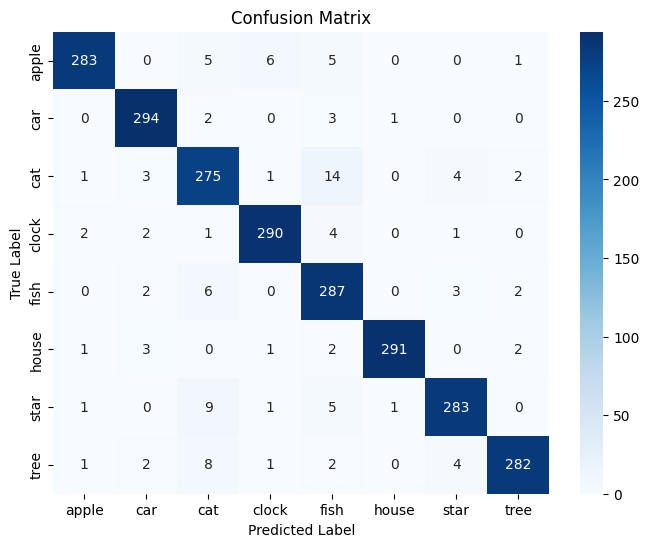

Model saved successfully as 'cnn_drawing_model.keras'


In [3]:
import time
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import layers, models

# Split dataset: 70% Training, 15% Validation, 15% Testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Training samples: {X_train.shape[0]} | Validation samples: {X_val.shape[0]} | Testing samples: {X_test.shape[0]}")

# Build the CNN Model Architecture
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Flatten(),

    # Dense Classifier Layers
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(len(CLASSES), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the CNN Model
print("\n--- Starting Model Training ---")
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)
    ]
)

# Evaluate Model Performance
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")

# Measure Inference Speed
sample_input = X_test[0:1]
start_time = time.time()
_ = model.predict(sample_input, verbose=0)
inference_ms = (time.time() - start_time) * 1000
print(f"Single Image Inference Time: {inference_ms:.2f} ms")

# Generate Classification Report (Precision, Recall, F1-score)
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=CLASSES))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Save the trained model
model.save('cnn_drawing_model.keras')
print("Model saved successfully as 'cnn_drawing_model.keras'")